# F8 — Peut-on battre la marche aléatoire ?
**Apprentissage supervisé · classification avec référence · niveau intermédiaire**

| | |
|---|---|
| **Sujet** | Prévoir le **sens** (hausse / baisse) du rendement de la séance suivante de l'indice **MASI** (Moroccan All Shares Index) à partir de l'historique de prix. |
| **Problématique** | Si les prix suivent une marche aléatoire, aucun modèle ne peut faire mieux qu'une règle triviale. Des algorithmes d'apprentissage supervisé, nourris d'indicateurs techniques, font-ils **significativement** mieux que cette référence, hors échantillon ? |
| **Objectif mesurable** | Sur le jeu de test chronologique (derniers 15 % des séances), obtenir une **précision supérieure à celle de la référence « marche aléatoire »** (toujours prédire la classe majoritaire du jeu d'entraînement), avec une p-valeur < 0,05 (test binomial exact unilatéral). Critères secondaires : précision équilibrée, MCC, AUC, test de McNemar, validation glissante (*walk-forward*) et rendement après coûts. |
| **Données** | `Moroccan_All_Shares_Historical_Data__1_.csv` : 1 988 séances quotidiennes, 02/01/2018 → 31/12/2025. |

> **Remarque sur la source.** L'intitulé du sujet mentionne « FRED SP500 », mais le fichier fourni contient l'indice **MASI**. Le notebook est donc réalisé sur le MASI ; seule la cellule de chargement (section 2) serait à adapter pour le S&P 500 de FRED (colonne unique `SP500`, séparateur décimal différent).

**Versions** : affichées dans la cellule de configuration ci-dessous.

## Configuration
Imports, graine aléatoire (`GRAINE = 42`) et chemins relatifs (le CSV doit être placé à côté du notebook ou dans `./data`).

In [8]:
import sys, platform, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             matthews_corrcoef, roc_auc_score, confusion_matrix)

warnings.filterwarnings("ignore")
GRAINE = 42
random.seed(GRAINE)
np.random.seed(GRAINE)

# Recherche des chemins relatifs existants, avec un repli (None) si aucun n'est trouvé
CHEMIN = next((p for p in [Path("/content/Moroccan All Shares Historical Data (1).csv"),
                           Path("data/Moroccan_All_Shares_Historical_Data__1_.csv")] if p.exists()), None)

if CHEMIN is None:
    raise FileNotFoundError("Le fichier 'Moroccan_All_Shares_Historical_Data__1_.csv' est introuvable. Veuillez l'importer dans l'environnement Colab (par exemple dans le dossier de gauche) avant d'exécuter la cellule.")

plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})

print("Python", platform.python_version())
for nom, mod in [("numpy", np), ("pandas", pd), ("scipy", scipy), ("scikit-learn", sklearn), ("matplotlib", matplotlib)]:
    print(f"{nom:13s}", mod.__version__)
print("GRAINE =", GRAINE, "| fichier :", CHEMIN)

Python 3.13.18
numpy         2.4.6
pandas        2.2.3
scipy         1.16.3
scikit-learn  1.6.1
matplotlib    3.10.0
GRAINE = 42 | fichier : /content/Moroccan All Shares Historical Data (1).csv


## 2. Jeu de données
**Chargement et vérifications** : dimensions, types, premières lignes, plage de dates et fréquence.

In [9]:
brut = pd.read_csv(CHEMIN)
print("Dimensions brutes :", brut.shape)
print("\nTypes bruts :")
print(brut.dtypes)
display(brut.head())

Dimensions brutes : (1988, 7)

Types bruts :
Date         object
Price        object
Open         object
High         object
Low          object
Vol.        float64
Change %     object
dtype: object


,Date,Price,Open,High,Low,Vol.,Change %
0,12/31/2025,"18,846.35","18,654.74","18,869.80","18,651.55",NaN,1.03%
1,12/30/2025,"18,654.74","18,386.49","18,672.90","18,386.49",NaN,1.46%
2,12/29/2025,"18,386.49","18,476.19","18,813.23","18,378.58",NaN,-0.49%
3,12/26/2025,"18,476.19","18,941.16","19,144.14","18,476.19",NaN,-2.45%
4,12/25/2025,"18,941.16","18,917.37","19,048.87","18,864.61",NaN,0.13%


In [10]:
df = brut.copy()
for c in ["Price", "Open", "High", "Low"]:
    df[c] = df[c].str.replace(",", "", regex=False).astype(float)
df["Change %"] = df["Change %"].str.rstrip("%").astype(float)
df["Date"] = pd.to_datetime(df["Date"], format="%m/%d/%Y")
df = df.sort_values("Date").reset_index(drop=True)      # ordre chronologique croissant

print("Types après conversion :")
print(df.dtypes)
print("\nPlage de dates :", df["Date"].min().date(), "→", df["Date"].max().date())
ecarts = df["Date"].diff().dt.days.dropna()
print("Écart médian entre séances :", ecarts.median(), "jour(s)")
print("Répartition des écarts (jours) :")
print(ecarts.value_counts().sort_index().to_string())
print("\nSéances par jour de semaine (0 = lundi) :")
print(df["Date"].dt.dayofweek.value_counts().sort_index().to_string())
print("\nSéances par année :")
print(df.groupby(df["Date"].dt.year).size().to_string())

Types après conversion :
Date        datetime64[ns]
Price              float64
Open               float64
High               float64
Low                float64
Vol.               float64
Change %           float64
dtype: object

Plage de dates : 2018-01-02 → 2025-12-31
Écart médian entre séances : 1.0 jour(s)
Répartition des écarts (jours) :
Date
1.0    1536
2.0      28
3.0     383
4.0      26
5.0      10
6.0       3
7.0       1

Séances par jour de semaine (0 = lundi) :
Date
0    396
1    397
2    397
3    400
4    398

Séances par année :
Date
2018    247
2019    246
2020    250
2021    249
2022    254
2023    249
2024    246
2025    247


**Constats.** 1 988 lignes × 7 colonnes ; le CSV est en ordre antéchronologique (le plus récent en premier) et tous les nombres sont des chaînes (séparateur de milliers « , », pourcentages avec « % »). Après conversion et tri chronologique : période du 02/01/2018 au 31/12/2025, **fréquence quotidienne en jours de bourse** (~248 séances par an). Les écarts de 3 jours correspondent aux week-ends (383 cas), ceux de 4 jours et plus aux jours fériés : il n'y a pas de séance manquante à reconstituer.

In [11]:
display(df.describe().T.round(2))
print("Valeurs manquantes par colonne :")
print(df.isna().sum().to_string())

,count,mean,min,25%,50%,75%,max,std
Date,1988,2021-12-31 01:10:59.154929664,2018-01-02 00:00:00,2020-01-07 18:00:00,2022-01-04 12:00:00,2023-12-25 06:00:00,2025-12-31 00:00:00,NaN
Price,1988.0,12703.959205,8987.89,11247.465,12107.875,13236.9725,20233.5,2359.926194
Open,1988.0,12699.080045,8987.89,11246.9275,12103.69,13232.655,20233.5,2355.860102
High,1988.0,12758.151167,9064.97,11296.8825,12160.37,13274.345,20340.23,2378.804814
Low,1988.0,12651.332746,8916.12,11199.7525,12057.195,13176.215,20133.01,2343.703562
Vol.,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Change %,1988.0,0.024074,-8.82,-0.3,0.04,0.36,5.45,0.774735


Valeurs manquantes par colonne :
Date           0
Price          0
Open           0
High           0
Low            0
Vol.        1988
Change %       0


**Description du jeu (colonnes)**

| Colonne | Signification | Unité / type |
|---|---|---|
| `Date` | Date de la séance | jour (format américain MM/JJ/AAAA) |
| `Price` | Cours de clôture du MASI | points d'indice |
| `Open`, `High`, `Low` | Ouverture, plus haut, plus bas | points d'indice |
| `Vol.` | Volume échangé | **entièrement vide** (100 % de NaN) |
| `Change %` | Variation en pourcentage de la clôture par rapport à la veille | % (arrondi à 2 décimales) |

Le MASI est un indice de capitalisation boursière pondéré par le flottant, regroupant l'ensemble des actions cotées à la Bourse de Casablanca. Le fichier est au format des exports d'Investing.com (source exacte à confirmer par l'auteur). Limites : une seule série, aucun volume, et une ouverture qui reprend presque toujours la clôture de la veille.

## 3. Exploration
### 3.1 Qualité des données
Pour chaque problème : méthode de détection → décision → justification.

In [12]:
# 1) Valeurs manquantes
print("Part de NaN dans Vol. :", df["Vol."].isna().mean())
# 2) Doublons
print("Dates dupliquées :", df["Date"].duplicated().sum(), "| lignes dupliquées :", df.duplicated().sum())
# 3) Cohérence OHLC
inco = ((df["High"] < df["Low"]) | (df["Price"] > df["High"]) | (df["Price"] < df["Low"]) |
        (df["Open"] > df["High"]) | (df["Open"] < df["Low"]))
print("Lignes OHLC incohérentes :", int(inco.sum()))
# 4) Cohérence de « Change % » avec le prix
df["rendement"] = np.log(df["Price"]).diff()                 # rendement log quotidien
ecart_chg = (df["Price"].pct_change() * 100 - df["Change %"]).abs()
print("Écart max |Change % publié − calculé| :", round(ecart_chg.max(), 4), "point de %  (arrondi à 2 décimales)")
# 5) Open vs clôture précédente
gap = (df["Open"] / df["Price"].shift(1) - 1) * 100
print("Part de séances où Open == clôture de la veille :", round((gap.abs() < 1e-9).mean(), 3))
# 6) Valeurs atypiques (rendements) : méthode MAD robuste + règle des 5 écarts-types
r = df["rendement"].dropna()
mad = stats.median_abs_deviation(r, scale="normal")
z_rob = (r - r.median()) / mad
masque = z_rob.abs() > 5
atyp = df.loc[masque[masque].index, ["Date", "Price", "Change %"]].assign(z_robuste=z_rob[masque].round(1))
print(f"\nRendements atypiques (|z robuste| > 5) : {len(atyp)} séances sur {len(r)}")
print(atyp.sort_values("Date").to_string(index=False))
print("Répartition par année :", atyp["Date"].dt.year.value_counts().sort_index().to_dict())

Part de NaN dans Vol. : 1.0
Dates dupliquées : 0 | lignes dupliquées : 0
Lignes OHLC incohérentes : 0
Écart max |Change % publié − calculé| : 0.0051 point de %  (arrondi à 2 décimales)
Part de séances où Open == clôture de la veille : 0.847

Rendements atypiques (|z robuste| > 5) : 31 séances sur 1987
      Date    Price  Change %  z_robuste
2020-03-06 11474.03     -3.05       -6.4
2020-03-09 10806.41     -5.82      -12.3
2020-03-10 11395.21      5.45       10.7
2020-03-12 10579.76     -6.70      -14.2
2020-03-16  9596.00     -8.82      -18.9
2020-03-17  9298.54     -3.10       -6.5
2020-03-18  8987.89     -3.34       -7.0
2020-03-19  9291.60      3.38        6.7
2020-03-20  9609.27      3.42        6.8
2020-03-23  9953.45      3.58        7.1
2020-03-25  9891.77     -2.72       -5.7
2020-06-17 10438.48      3.51        6.9
2020-12-21 11164.60     -3.09       -6.5
2022-02-24 12954.68     -4.11       -8.6
2022-03-07 12415.46     -2.89       -6.1
2022-05-10 12666.75     -2.44       -5.1


| Problème | Détection | Décision | Justification |
|---|---|---|---|
| **Valeurs manquantes** | `isna()` par colonne | `Vol.` (100 % de NaN) **supprimée** ; aucune autre valeur manquante | Une colonne vide n'apporte aucune information et ne peut pas être imputée sans l'inventer. |
| **Doublons** | Dates et lignes dupliquées | Aucun doublon : rien à faire | — |
| **Incohérences OHLC** | `Low ≤ Open, Price ≤ High` | 0 incohérence | Les prix sont fiables. |
| **`Change %` vs prix** | Écart avec la variation recalculée | Écart max 0,005 point, soit l'arrondi à 2 décimales : `Change %` est **redondante** et n'est pas utilisée ; on recalcule le rendement log depuis `Price`. | Éviter une variable arrondie et mieux contrôlée en interne. |
| **Ouverture** | Part de séances où `Open` = clôture de la veille | 84,7 % : `Open` est peu informative ; on ne garde que l'écart d'ouverture (*gap*) comme variable. | Limite de la source, à discuter en section 8. |
| **Valeurs atypiques** | z-score **robuste** (médiane/MAD) sur les rendements, seuil \|z\| > 5 | 31 séances (1,6 %) signalées, **toutes conservées** : 13 en 2020 (krach Covid-19 de mars 2020), 10 en 2025 (dont le choc du 7 avril 2025), etc. | En finance, une valeur extrême est le plus souvent réelle (krach, crise). Les supprimer retirerait précisément les épisodes où le risque se matérialise et biaiserait l'évaluation. On choisit des modèles/pipelines peu sensibles aux extrêmes (arbres) ou régularisés (L2). |

### 3.2 Statistiques descriptives utiles au problème
On étudie les propriétés des **rendements** : leur équilibre haussier/baissier, leur éventuelle autocorrélation (si elle est nulle, la marche aléatoire tient) et leur volatilité.

**Constats.** (i) 52,8 % des rendements sont positifs : un prédicteur « toujours hausse » est déjà un adversaire non trivial ; (ii) la distribution est très éloignée de la loi normale (asymétrie −1,55, kurtosis en excès ≈ 20,6, Jarque-Bera rejette la normalité) ; (iii) les rendements sont **faiblement mais significativement autocorrélés** (ρ₁ ≈ 0,126, ρ₂ ≈ 0,114, Ljung-Box à 10 retards : p ≈ 5·10⁻¹¹), ce qui contredit la marche aléatoire *stricte* ; (iv) les rendements au carré sont autocorrélés (ρ ≈ 0,20) : la volatilité est regroupée, avec un pic en mars 2020.

In [13]:
print("Statistiques des rendements log quotidiens :")
res = pd.Series({
    "moyenne (%)": r.mean() * 100, "écart-type (%)": r.std() * 100,
    "min (%)": r.min() * 100, "max (%)": r.max() * 100,
    "asymétrie": stats.skew(r), "kurtosis excès": stats.kurtosis(r),
    "part de jours > 0": (r > 0).mean(), "part de jours = 0": (r == 0).mean()}).round(4)
print(res.to_string())
jb = stats.jarque_bera(r)
print(f"\nJarque-Bera : stat = {jb.statistic:.1f}, p-valeur = {jb.pvalue:.2e}  → normalité rejetée")
def acf(x, nlags):
    x = np.asarray(x) - np.mean(x)
    return np.array([np.sum(x[k:] * x[:len(x) - k]) / np.sum(x * x) for k in range(1, nlags + 1)])
rho = acf(r, 10)
n = len(r)
Q = n * (n + 2) * np.sum(rho ** 2 / (n - np.arange(1, 11)))
print("Autocorrélations lags 1..10 :", np.round(rho, 3))
print(f"Ljung-Box (10 lags) : Q = {Q:.1f}, p-valeur = {1 - stats.chi2.cdf(Q, 10):.2e}")
print(f"Autocorrélation des rendements² (lag 1) : {acf(r**2, 1)[0]:.3f}  (regroupement de volatilité)")

Statistiques des rendements log quotidiens :
moyenne (%)           0.0210
écart-type (%)        0.7791
min (%)              -9.2317
max (%)               5.3054
asymétrie            -1.5497
kurtosis excès       20.6384
part de jours > 0     0.5279
part de jours = 0     0.0005

Jarque-Bera : stat = 36059.9, p-valeur = 0.00e+00  → normalité rejetée
Autocorrélations lags 1..10 : [ 0.126  0.114 -0.004 -0.038 -0.022 -0.001  0.037 -0.049  0.022  0.004]
Ljung-Box (10 lags) : Q = 69.9, p-valeur = 4.58e-11
Autocorrélation des rendements² (lag 1) : 0.197  (regroupement de volatilité)


### 3.3 Graphiques
*Haut gauche* : niveau du MASI (échelle log) et krach de mars 2020. *Haut droit* : queues épaisses par rapport à la loi normale. *Bas gauche* : autocorrélations aux retards 1 et 2 au-delà des bornes de bruit blanc. *Bas droit* : volatilité glissante, nettement plus forte en 2020.

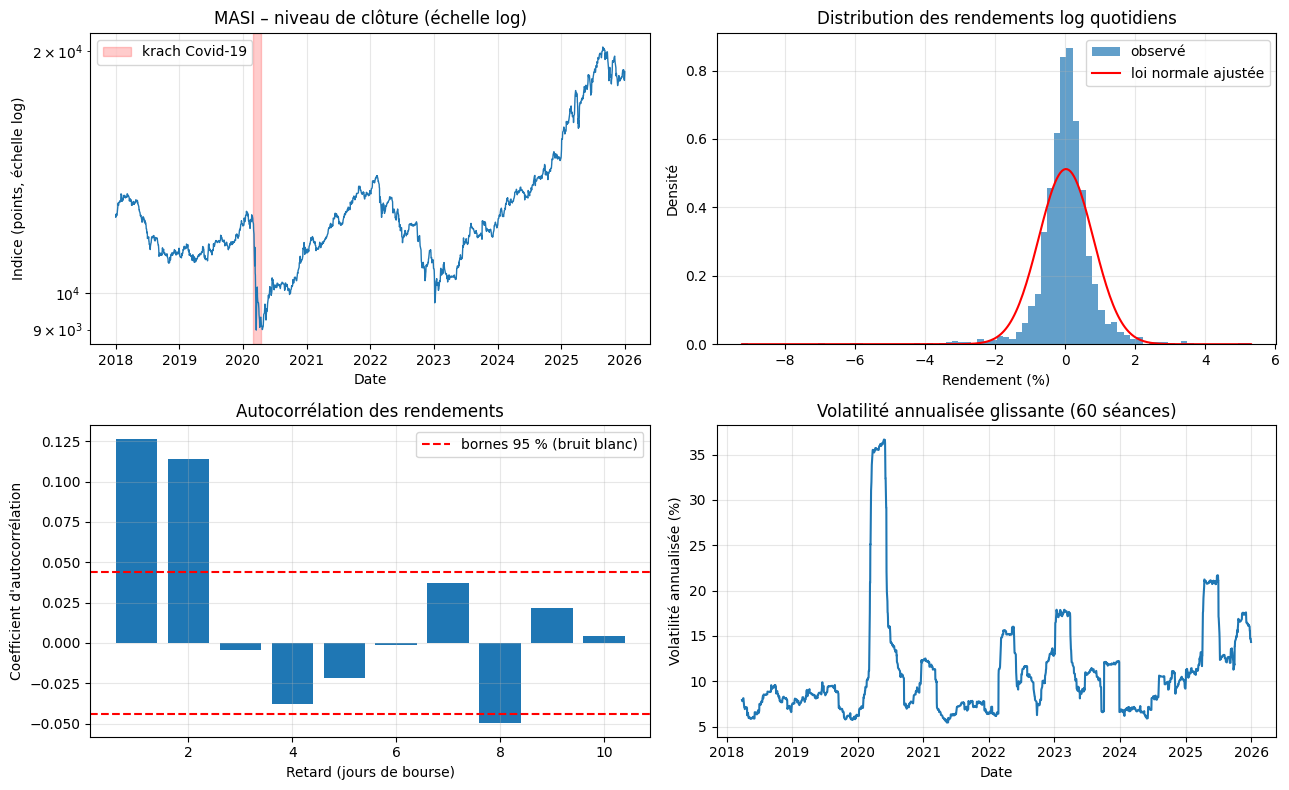

In [14]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
ax[0, 0].plot(df["Date"], df["Price"], lw=1)
ax[0, 0].set_yscale("log")
ax[0, 0].axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2020-04-15"), color="red", alpha=.2, label="krach Covid-19")
ax[0, 0].set(title="MASI – niveau de clôture (échelle log)", xlabel="Date", ylabel="Indice (points, échelle log)")
ax[0, 0].legend()
ax[0, 1].hist(r * 100, bins=80, density=True, alpha=.7, label="observé")
xs = np.linspace(r.min() * 100, r.max() * 100, 300)
ax[0, 1].plot(xs, stats.norm.pdf(xs, r.mean() * 100, r.std() * 100), "r", label="loi normale ajustée")
ax[0, 1].set(title="Distribution des rendements log quotidiens", xlabel="Rendement (%)", ylabel="Densité")
ax[0, 1].legend()
ax[1, 0].bar(range(1, 11), rho)
borne = 1.96 / np.sqrt(n)
ax[1, 0].axhline(borne, color="r", ls="--"); ax[1, 0].axhline(-borne, color="r", ls="--", label="bornes 95 % (bruit blanc)")
ax[1, 0].set(title="Autocorrélation des rendements", xlabel="Retard (jours de bourse)", ylabel="Coefficient d'autocorrélation")
ax[1, 0].legend()
ax[1, 1].plot(df["Date"], df["rendement"].rolling(60).std() * np.sqrt(252) * 100)
ax[1, 1].set(title="Volatilité annualisée glissante (60 séances)", xlabel="Date", ylabel="Volatilité annualisée (%)")
plt.tight_layout(); plt.show()

## 4. Préparation
- **Nettoyage** : tri chronologique, conversion des types, suppression de `Vol.` et de `Change %` (redondante) ; aucune valeur extrême supprimée (voir 3.1).
- **Cible** : `cible = 1` si le rendement log de la séance **suivante** est strictement positif, 0 sinon (le cas « = 0 » est quasi inexistant, 0,05 %).
- **Création de variables** (toutes calculables à la clôture de la séance *t*, donc sans fuite d'information du futur) : rendements retardés `r_lag0…r_lag4`, moyennes mobiles 5 et 20 jours, volatilités 5 et 20 jours, amplitude (High−Low)/Close, écart d'ouverture, momentum 10 jours, écart à la moyenne mobile 50 jours, RSI 14 jours. 50 lignes sont perdues au démarrage (fenêtre de 50 jours).
- **Encodage** : le jour de la semaine est encodé en *one-hot* (5 indicatrices), car c'est une variable catégorielle sans ordre naturel.
- **Mise à l'échelle** : **nécessaire pour la régression logistique** (la pénalité L2 et l'optimisation dépendent des échelles : sans standardisation, une variable en « points » écraserait une variable en « % ») ; **inutile pour les arbres** (forêt aléatoire, gradient boosting), qui ne dépendent que de l'ordre des valeurs. Le `StandardScaler` est **appris sur le train uniquement** (dans un `Pipeline`) puis appliqué à validation/test, pour éviter toute fuite.
- **Découpage chronologique** 70 % / 15 % / 15 % (pas de mélange aléatoire : on prédit le futur avec le passé), avec un **embargo d'une ligne** entre blocs, car la cible de la dernière ligne d'un bloc utilise le rendement de la première séance du bloc suivant.

In [15]:
d = df.copy()
r_ = d["rendement"]
X = pd.DataFrame(index=d.index)
for k in range(5):
    X[f"r_lag{k}"] = r_.shift(k)                     # r_lag0 = rendement du jour t (connu à la clôture)
X["moy_5"] = r_.rolling(5).mean()
X["moy_20"] = r_.rolling(20).mean()
X["vol_5"] = r_.rolling(5).std()
X["vol_20"] = r_.rolling(20).std()
X["amplitude"] = (d["High"] - d["Low"]) / d["Price"]
X["ecart_ouverture"] = d["Open"] / d["Price"].shift(1) - 1
X["momentum_10"] = np.log(d["Price"] / d["Price"].shift(10))
X["ecart_mm50"] = d["Price"] / d["Price"].rolling(50).mean() - 1
delta = d["Price"].diff()
gain = delta.clip(lower=0).rolling(14).mean(); perte = (-delta.clip(upper=0)).rolling(14).mean()
X["rsi_14"] = 100 - 100 / (1 + gain / perte)
jours = pd.get_dummies(d["Date"].dt.dayofweek, prefix="jour", dtype=int)   # encodage one-hot
X = pd.concat([X, jours], axis=1)

# Cible : le rendement de LA SÉANCE SUIVANTE est-il positif ?  (1 = hausse, 0 = baisse ou nul)
y = (r_.shift(-1) > 0).astype(float)
y[r_.shift(-1).isna()] = np.nan

base = pd.concat([d[["Date"]], X, y.rename("cible")], axis=1).dropna().reset_index(drop=True)
COL_CONT = [c for c in X.columns if not c.startswith("jour_")]
COL_VAR = list(X.columns)
print("Table finale :", base.shape, "| variables :", len(COL_VAR))
print("Période :", base["Date"].min().date(), "→", base["Date"].max().date())
print("Équilibre des classes (part de hausses) :", round(base["cible"].mean(), 4))
print("Fenêtre perdue au démarrage (calcul des indicateurs) :", len(d) - len(base), "lignes")

Table finale : (1938, 21) | variables : 19
Période : 2018-03-13 → 2025-12-30
Équilibre des classes (part de hausses) : 0.5263
Fenêtre perdue au démarrage (calcul des indicateurs) : 50 lignes


In [16]:
n = len(base)
i1, i2 = int(n * 0.70), int(n * 0.85)
tr, va, te = base.iloc[:i1], base.iloc[i1:i2], base.iloc[i2:]
for nom, part in [("train", tr), ("validation", va), ("test", te)]:
    print(f"{nom:10s} {len(part):5d} lignes  {part['Date'].min().date()} → {part['Date'].max().date()}  part de hausses = {part['cible'].mean():.3f}")
Xtr, ytr = tr[COL_VAR], tr["cible"].astype(int)
Xva, yva = va[COL_VAR], va["cible"].astype(int)
Xte, yte = te[COL_VAR], te["cible"].astype(int)
# La cible de la ligne t utilise le rendement t+1 ; la dernière ligne de chaque bloc partage donc
# une information avec la première du bloc suivant : on neutralise cette fuite avec un embargo d'1 ligne.
Xva, yva = Xva.iloc[1:], yva.iloc[1:]
Xte, yte = Xte.iloc[1:], yte.iloc[1:]

train       1356 lignes  2018-03-13 → 2023-08-22  part de hausses = 0.507
validation   291 lignes  2023-08-23 → 2024-10-25  part de hausses = 0.553
test         291 lignes  2024-10-28 → 2025-12-30  part de hausses = 0.588


## 5. Algorithmes
| Modèle | Rôle | Pourquoi |
|---|---|---|
| **Référence « marche aléatoire »** | Adversaire principal | Sans information exploitable, le meilleur pari est la classe majoritaire du train (dérive positive). |
| Référence tirage pondéré | Contrôle | Prédire au hasard selon les fréquences du train. |
| Référence persistance | Contrôle naïf | « Demain aura le même signe qu'aujourd'hui » : teste directement l'autocorrélation observée. |
| **Régression logistique** (L2) | Modèle linéaire, interprétable | Variables standardisées ; coefficient `C` choisi sur la validation. |
| **Forêt aléatoire** | Modèle non linéaire robuste | Profondeur limitée (2–5) et feuilles minimales (20/50) pour limiter le surapprentissage sur un signal faible. |
| **Gradient boosting** (`HistGradientBoosting`) | Modèle non linéaire séquentiel | Arbres peu profonds, faible taux d'apprentissage. |

## 6. Protocole
1. **Hyperparamètres** choisis sur la **validation** (critère : précision équilibrée, adaptée à des classes légèrement déséquilibrées), jamais sur le test.
2. **Réentraînement** de chaque modèle sur train + validation, puis **évaluation unique** sur le test (graine 42 partout).
3. **Métriques** : précision, précision équilibrée, F1, MCC, AUC.
4. **Significativité** : test binomial exact (contre 50 % et contre la référence majoritaire), intervalle de Wilson à 95 %, test de McNemar exact (modèle contre référence).
5. **Robustesse** : validation glissante *walk-forward* (2021-2025, réentraînement tous les 63 séances, fenêtre croissante), car 290 séances de test donnent un intervalle de ±5,6 points environ.
6. **Lecture économique** : stratégie « long si hausse prédite, sinon liquidités » avec un coût de 0,10 % par changement de position (hypothèse), comparée à l'achat-conservation.

### 6.1 Choix des hyperparamètres (validation)

In [17]:
def preproc(echelle):
    # La mise à l'échelle est apprise sur le TRAIN uniquement (dans le pipeline), jamais sur val/test.
    return ColumnTransformer([("sc", StandardScaler() if echelle else "passthrough", COL_CONT)],
                             remainder="passthrough")

def metriques(y_vrai, y_pred, proba=None):
    m = {"accuracy": accuracy_score(y_vrai, y_pred),
         "acc_equilibree": balanced_accuracy_score(y_vrai, y_pred),
         "F1": f1_score(y_vrai, y_pred, zero_division=0),
         "MCC": matthews_corrcoef(y_vrai, y_pred)}
    m["AUC"] = roc_auc_score(y_vrai, proba) if proba is not None else np.nan
    return m

grilles = {
    "Régression logistique": (lambda **p: Pipeline([("pre", preproc(True)),
                              ("m", LogisticRegression(max_iter=2000, random_state=GRAINE, **p))]),
                              [{"C": c} for c in [0.001, 0.01, 0.1, 1, 10]]),
    "Forêt aléatoire": (lambda **p: Pipeline([("pre", preproc(False)),
                        ("m", RandomForestClassifier(n_estimators=300, random_state=GRAINE, n_jobs=-1, **p))]),
                        [{"max_depth": d_, "min_samples_leaf": l} for d_ in [2, 3, 5] for l in [20, 50]]),
    "Gradient boosting": (lambda **p: Pipeline([("pre", preproc(False)),
                          ("m", HistGradientBoostingClassifier(random_state=GRAINE, **p))]),
                          [{"max_depth": d_, "learning_rate": lr, "max_iter": it, "min_samples_leaf": 30}
                           for d_ in [2, 3] for lr in [0.03, 0.1] for it in [50, 150]]),
}
choix = {}
lignes = []
for nom, (fabrique, grille) in grilles.items():
    meilleur = None
    for p in grille:
        mod = fabrique(**p).fit(Xtr, ytr)
        proba = mod.predict_proba(Xva)[:, 1]
        pred = (proba >= 0.5).astype(int)
        score = balanced_accuracy_score(yva, pred)
        lignes.append({"modèle": nom, "hyperparamètres": str(p), "acc_équilibrée_val": round(score, 4),
                       "AUC_val": round(roc_auc_score(yva, proba), 4)})
        if meilleur is None or score > meilleur[0]:
            meilleur = (score, p)
    choix[nom] = meilleur[1]
print(pd.DataFrame(lignes).sort_values(["modèle", "acc_équilibrée_val"], ascending=[True, False]).to_string(index=False))
print("\nHyperparamètres retenus (validation) :")
for k, v in choix.items(): print(" -", k, v)

               modèle                                                                  hyperparamètres  acc_équilibrée_val  AUC_val
      Forêt aléatoire                                         {'max_depth': 5, 'min_samples_leaf': 20}              0.5423   0.5436
      Forêt aléatoire                                         {'max_depth': 5, 'min_samples_leaf': 50}              0.5416   0.5452
      Forêt aléatoire                                         {'max_depth': 3, 'min_samples_leaf': 20}              0.5389   0.5504
      Forêt aléatoire                                         {'max_depth': 3, 'min_samples_leaf': 50}              0.5334   0.5488
      Forêt aléatoire                                         {'max_depth': 2, 'min_samples_leaf': 50}              0.5315   0.5516
      Forêt aléatoire                                         {'max_depth': 2, 'min_samples_leaf': 20}              0.5130   0.5544
    Gradient boosting  {'max_depth': 2, 'learning_rate': 0.1, 'max_iter': 15

## 7. Résultats
### 7.1 Test chronologique (jamais vu pendant la sélection)

In [18]:
Xdev = pd.concat([Xtr, Xva]); ydev = pd.concat([ytr, yva])
resultats, predictions, probas = {}, {}, {}

# --- Références ---
maj = DummyClassifier(strategy="most_frequent").fit(Xdev, ydev)
alea = DummyClassifier(strategy="stratified", random_state=GRAINE).fit(Xdev, ydev)
predictions["Réf. marche aléatoire (classe majoritaire)"] = maj.predict(Xte)
predictions["Réf. tirage aléatoire pondéré"] = alea.predict(Xte)
# Persistance : « demain = signe d'aujourd'hui » (rendement du jour t = r_lag0)
predictions["Réf. persistance (signe de la veille)"] = (Xte["r_lag0"] > 0).astype(int).values
probas["Réf. persistance (signe de la veille)"] = Xte["r_lag0"].values

# --- Modèles (réentraînés sur train+validation avec les hyperparamètres choisis) ---
for nom, (fabrique, _) in grilles.items():
    mod = fabrique(**choix[nom]).fit(Xdev, ydev)
    probas[nom] = mod.predict_proba(Xte)[:, 1]
    predictions[nom] = (probas[nom] >= 0.5).astype(int)

for nom, pred in predictions.items():
    resultats[nom] = metriques(yte, pred, probas.get(nom))
tab = pd.DataFrame(resultats).T.round(4)
display(tab)
print("\nTest :", len(yte), "séances,", Xte.index.size, "| part de hausses :", round(yte.mean(), 4))

,accuracy,acc_equilibree,F1,MCC,AUC
Réf. marche aléatoire (classe majoritaire),0.5862,0.5000,0.7391,0.0000,NaN
Réf. tirage aléatoire pondéré,0.4621,0.4603,0.5063,-0.0782,NaN
Réf. persistance (signe de la veille),0.5793,0.5664,0.6412,0.1328,0.6018
Régression logistique,0.5345,0.5159,0.6110,0.0322,0.5338
Forêt aléatoire,0.5310,0.5179,0.5976,0.0357,0.5326
Gradient boosting,0.4931,0.5027,0.5084,0.0053,0.5307



Test : 290 séances, 290 | part de hausses : 0.5862


**Lecture.** Sur le test, la référence « toujours hausse » atteint **58,6 %** car la période (oct. 2024 → déc. 2025) est fortement haussière (58,8 % de séances positives). Les trois modèles font moins bien : régression logistique 53,4 %, forêt 53,1 %, gradient boosting 50,3 %. Leur précision équilibrée (≈ 0,51-0,52), leur MCC (≈ 0,02-0,04) et leur AUC (≈ 0,52-0,53) sont proches du hasard. La persistance obtient la meilleure AUC (0,60) et le meilleur MCC (0,13).

### 7.2 Significativité statistique

In [19]:
ref_nom = "Réf. marche aléatoire (classe majoritaire)"
ref_pred = predictions[ref_nom]
p0 = accuracy_score(yte, ref_pred)
print(f"Précision de la référence (toujours « hausse ») sur le test : {p0:.4f}\n")
lig = []
for nom in ["Régression logistique", "Forêt aléatoire", "Gradient boosting", "Réf. persistance (signe de la veille)"]:
    pred = predictions[nom]
    k = int((pred == yte.values).sum()); N = len(yte)
    ic = stats.binomtest(k, N).proportion_ci(0.95, method="wilson")
    p_bin = stats.binomtest(k, N, 0.5, alternative="greater").pvalue          # vs hasard pur 50 %
    p_ref = stats.binomtest(k, N, p0, alternative="greater").pvalue           # vs référence majoritaire
    b = int(((pred == yte.values) & (ref_pred != yte.values)).sum())          # modèle juste, réf. fausse
    c = int(((pred != yte.values) & (ref_pred == yte.values)).sum())          # modèle faux, réf. juste
    p_mc = stats.binomtest(b, b + c, 0.5).pvalue if b + c > 0 else np.nan     # McNemar exact (bilatéral)
    lig.append({"modèle": nom, "précision": round(k / N, 4), "IC95 bas": round(ic.low, 3), "IC95 haut": round(ic.high, 3),
                "p (>50 %)": round(p_bin, 3), "p (> réf. majoritaire)": round(p_ref, 3), "p McNemar vs réf.": round(p_mc, 3)})
print(pd.DataFrame(lig).to_string(index=False))

Précision de la référence (toujours « hausse ») sur le test : 0.5862

                               modèle  précision  IC95 bas  IC95 haut  p (>50 %)  p (> réf. majoritaire)  p McNemar vs réf.
                Régression logistique     0.5345     0.477      0.591      0.132                   0.967              0.188
                      Forêt aléatoire     0.5310     0.474      0.588      0.159                   0.975              0.174
                    Gradient boosting     0.4931     0.436      0.550      0.615                   0.999              0.040
Réf. persistance (signe de la veille)     0.5793     0.522      0.635      0.004                   0.618              0.927


**Lecture.** Aucun modèle ne dépasse la référence majoritaire (p ≈ 0,97 à 1,00). Aucun n'est non plus significativement meilleur que 50 % (p = 0,13 ; 0,16 ; 0,48). Seule la persistance bat 50 % (p = 0,004) mais pas la référence majoritaire (p = 0,62). Les écarts avec la référence ne sont pas significatifs au sens de McNemar (p ≥ 0,065).

### 7.3 Robustesse : validation glissante (walk-forward, 2021-2025)

In [20]:
# Robustesse : validation « glissante » (walk-forward) sur 2021-2025, réentraînement tous les 63 séances,
# fenêtre croissante, hyperparamètres figés (choisis ci-dessus).
DEB = base.index[base["Date"] >= "2021-01-01"][0]
PAS = 63
res_wf = {nom: [] for nom in list(grilles) + ["Réf. majoritaire", "Persistance"]}
vrai_wf = []
for debut in range(DEB, len(base) - 1, PAS):
    fin = min(debut + PAS, len(base))
    app = base.iloc[:debut - 1]                       # embargo d'1 ligne
    tst = base.iloc[debut:fin]
    vrai_wf.append(tst["cible"].astype(int).values)
    for nom, (fabrique, _) in grilles.items():
        res_wf[nom].append(fabrique(**choix[nom]).fit(app[COL_VAR], app["cible"].astype(int)).predict(tst[COL_VAR]))
    res_wf["Réf. majoritaire"].append(np.full(len(tst), int(app["cible"].mean() >= 0.5)))
    res_wf["Persistance"].append((tst["r_lag0"] > 0).astype(int).values)
vrai_wf = np.concatenate(vrai_wf)
lig = []
base_maj = np.concatenate(res_wf["Réf. majoritaire"])
for nom, morceaux in res_wf.items():
    pred = np.concatenate(morceaux)
    k = int((pred == vrai_wf).sum()); N = len(vrai_wf)
    b = int(((pred == vrai_wf) & (base_maj != vrai_wf)).sum()); c = int(((pred != vrai_wf) & (base_maj == vrai_wf)).sum())
    lig.append({"méthode": nom, "N": N, "précision": round(k / N, 4),
                "acc_équilibrée": round(balanced_accuracy_score(vrai_wf, pred), 4),
                "p (> 50 %)": round(stats.binomtest(k, N, 0.5, alternative="greater").pvalue, 4),
                "p McNemar vs réf.": round(stats.binomtest(b, b + c, 0.5).pvalue, 4) if b + c else np.nan})
print(pd.DataFrame(lig).to_string(index=False))

              méthode    N  précision  acc_équilibrée  p (> 50 %)  p McNemar vs réf.
Régression logistique 1244     0.5442          0.5335      0.0010             0.5626
      Forêt aléatoire 1244     0.5619          0.5554      0.0000             0.1320
    Gradient boosting 1244     0.5330          0.5341      0.0108             1.0000
     Réf. majoritaire 1244     0.5330          0.5005      0.0108                NaN
          Persistance 1244     0.5514          0.5475      0.0002             0.3614


**Lecture.** Sur 1 244 séances, les modèles font légèrement mieux que la référence (53,3 %) : forêt 56,1 %, persistance 55,1 %, régression logistique 54,4 %, gradient boosting 53,8 %. Ils battent clairement 50 % mais cela reflète surtout la dérive haussière ; **contre la référence majoritaire, aucune différence n'est significative** (McNemar p = 0,14 pour la forêt, la meilleure). Précaution : les hyperparamètres ont été choisis sur une période (validation) qui fait partie de ces plis, ce qui avantage légèrement les modèles.

### 7.4 Graphiques de résultats

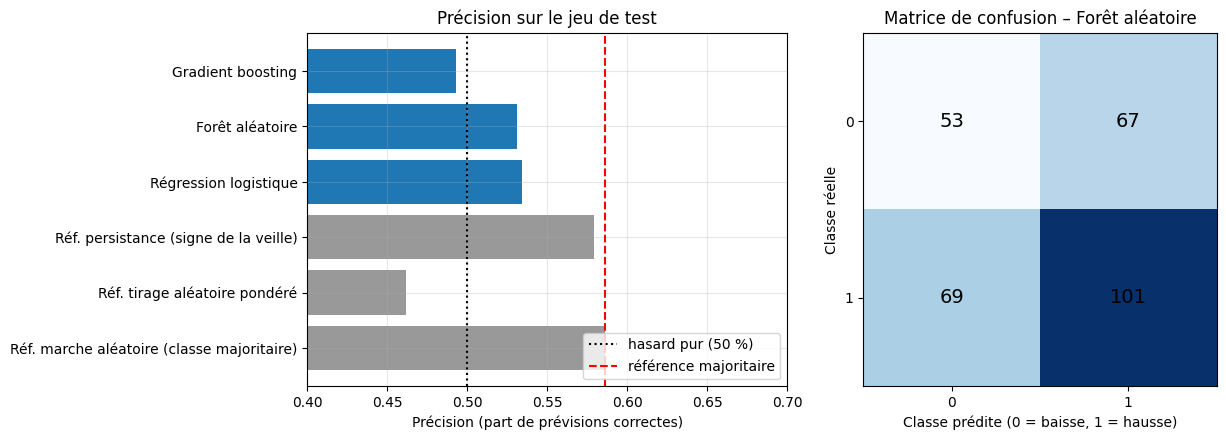

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
noms = list(tab.index)
ax[0].barh(noms, tab["accuracy"], color=["#999"] * 3 + ["#1f77b4"] * 3)
ax[0].axvline(0.5, color="k", ls=":", label="hasard pur (50 %)")
ax[0].axvline(p0, color="r", ls="--", label="référence majoritaire")
ax[0].set(title="Précision sur le jeu de test", xlabel="Précision (part de prévisions correctes)", xlim=(0.4, max(0.7, tab['accuracy'].max() + .03)))
ax[0].legend(loc="lower right")
meilleur_nom = tab.loc[["Régression logistique", "Forêt aléatoire", "Gradient boosting"], "acc_equilibree"].idxmax()
cm = confusion_matrix(yte, predictions[meilleur_nom])
ax[1].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm): ax[1].text(j, i, v, ha="center", va="center", fontsize=14)
ax[1].set(title=f"Matrice de confusion – {meilleur_nom}", xlabel="Classe prédite (0 = baisse, 1 = hausse)", ylabel="Classe réelle",
          xticks=[0, 1], yticks=[0, 1]); ax[1].grid(False)
plt.tight_layout(); plt.show()

### 7.5 Variables les plus influentes

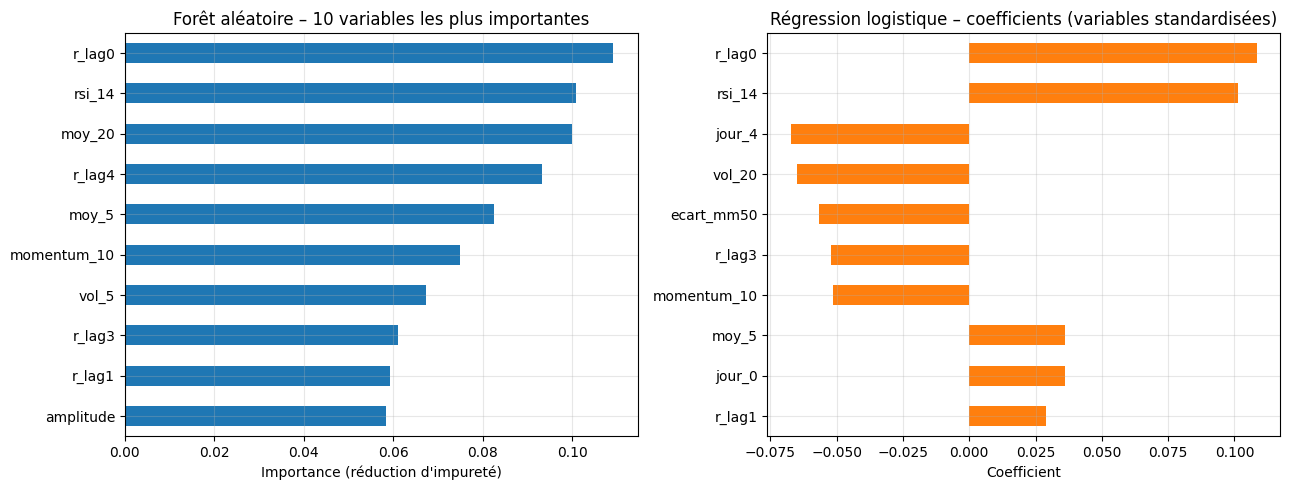

In [22]:
rf = grilles["Forêt aléatoire"][0](**choix["Forêt aléatoire"]).fit(Xdev, ydev)
noms_var = COL_CONT + [c for c in COL_VAR if c not in COL_CONT]
imp = pd.Series(rf.named_steps["m"].feature_importances_, index=noms_var).sort_values()
lr = grilles["Régression logistique"][0](**choix["Régression logistique"]).fit(Xdev, ydev)
coef = pd.Series(lr.named_steps["m"].coef_[0], index=noms_var).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
imp.tail(10).plot.barh(ax=ax[0]); ax[0].set(title="Forêt aléatoire – 10 variables les plus importantes", xlabel="Importance (réduction d'impureté)")
coef.reindex(coef.abs().sort_values().tail(10).index).plot.barh(ax=ax[1], color="C1")
ax[1].set(title="Régression logistique – coefficients (variables standardisées)", xlabel="Coefficient")
plt.tight_layout(); plt.show()

**Lecture.** Dans les deux modèles, les variables dominantes sont le **rendement du jour (`r_lag0`)** et le **RSI 14 jours** (coefficients positifs en régression logistique : continuation du mouvement récent), ce qui rejoint l'autocorrélation positive de la section 3. La forêt utilise aussi `moy_20`, `r_lag4` et `moy_5`. Ces importances décrivent le modèle, pas une causalité ni un signal exploitable.

### 7.6 Lecture économique (backtest simplifié sur le test)

            stratégie  rendement cumulé (%)  Sharpe annualisé  nb de changements
Régression logistique                 21.53              1.73                100
      Forêt aléatoire                 16.68              1.18                118
    Gradient boosting                 10.69              0.88                120
    Acheter-conserver                 32.28              1.68                  0


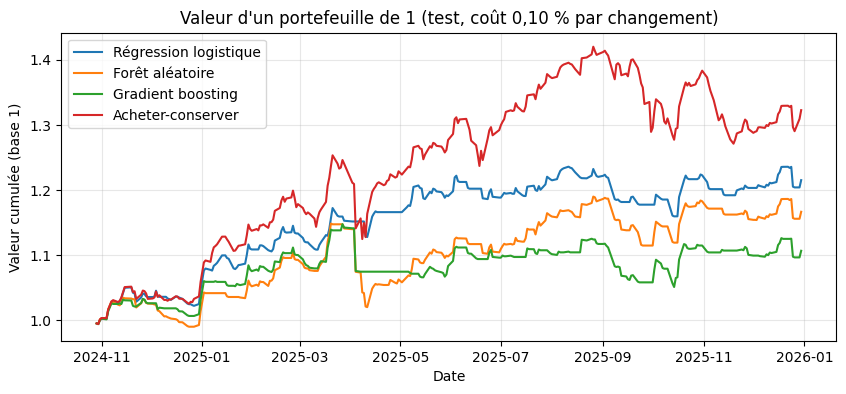

In [23]:
rend_te = te["Date"].iloc[1:].to_frame()
rend_te["r_suivant"] = np.exp(np.log(df.set_index("Date")["Price"]).diff().shift(-1).reindex(rend_te["Date"]).values) - 1
cout = 0.001                                           # 0,10 % par changement de position (hypothèse)
lig = []
courbes = {}
for nom in ["Régression logistique", "Forêt aléatoire", "Gradient boosting"]:
    pos = pd.Series(predictions[nom], index=rend_te.index)
    nb_chg = pos.diff().abs().fillna(0)
    ret = pos * rend_te["r_suivant"] - nb_chg * cout
    courbes[nom] = (1 + ret).cumprod()
    lig.append({"stratégie": nom, "rendement cumulé (%)": round((courbes[nom].iloc[-1] - 1) * 100, 2),
                "Sharpe annualisé": round(ret.mean() / ret.std() * np.sqrt(252), 2) if ret.std() > 0 else np.nan,
                "nb de changements": int(nb_chg.sum())})
bh = (1 + rend_te["r_suivant"]).cumprod(); courbes["Acheter-conserver"] = bh
ret_bh = rend_te["r_suivant"]
lig.append({"stratégie": "Acheter-conserver", "rendement cumulé (%)": round((bh.iloc[-1] - 1) * 100, 2),
            "Sharpe annualisé": round(ret_bh.mean() / ret_bh.std() * np.sqrt(252), 2), "nb de changements": 0})
print(pd.DataFrame(lig).to_string(index=False))
plt.figure(figsize=(10, 4))
for nom, c in courbes.items(): plt.plot(rend_te["Date"].values, c.values, label=nom)
plt.title("Valeur d'un portefeuille de 1 (test, coût 0,10 % par changement)"); plt.xlabel("Date"); plt.ylabel("Valeur cumulée (base 1)")
plt.legend(); plt.show()

**Lecture.** Après coûts supposés de 0,10 %, aucune stratégie ne dépasse l'achat-conservation en rendement cumulé (+32,3 %) ; la régression logistique obtient +21,5 % avec un Sharpe de 1,73 contre 1,68, écart trop faible pour être conclu sur 290 séances. Les stratégies restent investies en moyenne moins longtemps dans un marché très haussier, d'où leur retard.

## 8. Analyse critique
- **Réponse à la question.** La marche aléatoire *stricte* est rejetée statistiquement pour le MASI (autocorrélation de rendement significative, ρ₁ ≈ 0,13), mais **nous ne démontrons pas qu'on puisse la battre de façon exploitable** : sur le test, aucun modèle ne dépasse la référence majoritaire ; en validation glissante, la meilleure (forêt, +2,8 points) n'est pas significative (p = 0,14).
- **Puissance limitée.** Avec ~290 observations, l'intervalle à 95 % de la précision est d'environ ±5,6 points : un avantage réel de 2-3 points est indétectable. Absence de preuve ≠ preuve d'absence.
- **Sensibilité à la période.** La référence dépend de la part de hausses (50,7 % train, 55,3 % validation, 58,8 % test) : un marché haussier favorise « toujours hausse ». Les résultats peuvent s'inverser dans un marché baissier.
- **Comparaisons multiples.** Trois familles de modèles et ~20 configurations ont été essayées : le risque de faux positif augmente ; les p-valeurs ne sont pas corrigées.
- **Fuite résiduelle.** Les hyperparamètres choisis sur la validation sont réutilisés dans le *walk-forward* (qui recouvre cette période) : légère optimisme possible. L'embargo d'une ligne traite le chevauchement de cible, mais pas la dépendance sérielle de la volatilité.
- **Données.** Pas de volume, ouverture quasi toujours égale à la clôture de la veille, une seule série, indice non directement négociable (ETF/frais, liquidité, écarts de prix non modélisés). Le MASI peut subir un effet de cotation peu fréquente sur certaines valeurs, hypothèse plausible pour l'autocorrélation mais **non testée ici**.
- **Coûts.** Les 0,10 % sont une hypothèse ; la fiscalité et les frais réels peuvent dégrader davantage les stratégies actives (100-124 changements de position sur le test).
- **Pistes.** Classes de rendement avec seuil (ignorer les petites variations), modèles de volatilité (GARCH), plus d'actifs, correction des tests multiples.

## 9. Conclusion
Sur le MASI (2018-2025), **les modèles d'apprentissage supervisé testés (régression logistique, forêt aléatoire, gradient boosting) ne battent pas de façon significative la référence « marche aléatoire »** (classe majoritaire) pour prédire le sens du rendement du lendemain : sur le test, 50,3 % à 53,4 % contre 58,6 % pour la référence ; en walk-forward, au mieux 56,1 % contre 53,3 %, sans significativité (p = 0,14). L'objectif mesurable fixé en section 1 **n'est donc pas atteint**. Le MASI présente néanmoins une autocorrélation de court terme significative, qui justifie des études complémentaires plus puissantes (plus d'actifs, plus de période, coûts réalistes).

## 10. Références
- Fama, E. F. (1970). *Efficient Capital Markets: A Review of Theory and Empirical Work*. The Journal of Finance, 25(2), 383-417.
- Lo, A. W. & MacKinlay, A. C. (1988). *Stock Market Prices Do Not Follow Random Walks: Evidence from a Simple Specification Test*. The Review of Financial Studies, 1(1), 41-66.
- Ljung, G. M. & Box, G. E. P. (1978). *On a Measure of Lack of Fit in Time Series Models*. Biometrika, 65(2), 297-303.
- McNemar, Q. (1947). *Note on the sampling error of the difference between correlated proportions or percentages*. Psychometrika, 12(2), 153-157.
- Bergmeir, C. & Benítez, J. M. (2012). *On the use of cross-validation for time series predictor evaluation*. Information Sciences, 191, 192-213.
- Pedregosa, F. et al. (2011). *Scikit-learn: Machine Learning in Python*. Journal of Machine Learning Research, 12, 2825-2830.
- Hastie, T., Tibshirani, R. & Friedman, J. (2009). *The Elements of Statistical Learning* (2e éd.). Springer.
- Données : fichier `Moroccan_All_Shares_Historical_Data__1_.csv` fourni pour le projet (indice MASI, Bourse de Casablanca ; export de type Investing.com).

## Déclaration des ressources et outils d'IA


Un assistant d'IA générative (Claude, Anthropic) a été utilisé pour produire une première version de la structure du notebook, du code Python et des commentaires, à partir de la consigne et du fichier de données fournis. Le code a été exécuté de bout en bout (Python 3.12, graine 42) et les résultats présentés proviennent de cette exécution. Les choix de conception (cible, variables, protocole chronologique, tests) doivent être compris, vérifiés et assumés par l'auteur. Aucune donnée externe n'a été utilisée en dehors du fichier fourni.